### Tarea 3 Big Data

**Estudiante: Dana Chavarría Corrales**


### 1 Dominio del problema
El conjunto de datos corresponde a campañas de **marketing directo por llamadas telefónicas** de una institución bancaria portuguesa. En cada llamada, el banco ofrecía al cliente un **depósito a plazo**. El objetivo del problema es predecir si un cliente contratará o no ese depósito, a partir de sus características personales, su historial financiero y la información de los contactos previos de la campaña.

Resolver este problema ayuda al banco a priorizar a qué clientes llamar, con lo que reduce costos y mejora la tasa de éxito de sus campañas.

### Fuente y cita
- **Repositorio:** UCI Machine Learning Repository – Bank Marketing. https://archive.ics.uci.edu/dataset/222/bank+marketing
- **Archivo utilizado:** Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306.


### Tamaño del conjunto de datos
- 4 521 registros y 17 columnas (16 atributos de entrada y 1 variable objetivo).
- Los datos corresponden a contactos realizados entre 2008 y 2010.

## 2. Datos de entrada

### Variable a predecir
**`y`**: indica si el cliente contrató el depósito a plazo (`yes`) o no (`no`). Es un problema de **clasificación binaria**. Para el modelo, `y` se transforma a una columna numérica con valores 0 (`no`) y 1 (`yes`).

La clase positiva es minoritaria: hay 521 registros `yes` (11.5 %) frente a 4 000 `no` (88.5 %), por lo que el conjunto de datos está **desbalanceado**. Por esto se utilizan métricas como AUC y F1 además de la exactitud (*accuracy*).

### Descripción de las columnas

| # | Columna | Tipo (Spark) | Naturaleza | Descripción |
|---|---------|--------------|------------|-------------|
| 1 | `age` | Integer | Numérica | Edad del cliente. |
| 2 | `job` | String | Categórica | Tipo de trabajo (admin., blue-collar, entrepreneur, housemaid, management, retired, self-employed, services, student, technician, unemployed, unknown). |
| 3 | `marital` | String | Categórica | Estado civil (married, single, divorced). |
| 4 | `education` | String | Categórica | Nivel educativo (primary, secondary, tertiary, unknown). |
| 5 | `default` | String | Categórica binaria | Indica si el cliente tiene crédito en mora (yes/no). |
| 6 | `balance` | Integer | Numérica | Saldo promedio anual de la cuenta, en euros. |
| 7 | `housing` | String | Categórica binaria | Indica si tiene préstamo hipotecario (yes/no). |
| 8 | `loan` | String | Categórica binaria | Indica si tiene préstamo personal (yes/no). |
| 9 | `contact` | String | Categórica | Medio del último contacto (cellular, telephone, unknown). |
| 10 | `day` | Integer | Numérica | Día del mes del último contacto. |
| 11 | `month` | String | Categórica | Mes del último contacto (jan–dec). |
| 12 | `duration` | Integer | Numérica | Duración del último contacto, en segundos. |
| 13 | `campaign` | Integer | Numérica | Número de contactos realizados al cliente durante esta campaña (incluye el último). |
| 14 | `pdays` | Integer | Numérica | Días transcurridos desde el último contacto de una campaña anterior (`-1` = no fue contactado antes). |
| 15 | `previous` | Integer | Numérica | Número de contactos realizados antes de esta campaña. |
| 16 | `poutcome` | String | Categórica | Resultado de la campaña anterior (success, failure, other, unknown). |
| 17 | `y` | String → Integer | **Objetivo** | Si el cliente contrató el depósito a plazo (yes/no → 1/0). |

### Consideraciones sobre los datos
- **`duration` se excluye del modelo.** Su valor se conoce solo después de terminar la llamada, y la duración ya determina en gran parte el resultado. Usarla provocaría fuga de información (*data leakage*) y un modelo que no sirve para predecir antes de llamar.
- **`unknown`** aparece como categoría en varias columnas (`job`, `education`, `contact`, `poutcome`) y se trata en la fase de limpieza.
- **`pdays = -1`** representa "sin contacto previo" y no una cantidad de días, por lo que se trata de forma especial antes de normalizar.
- Los textos del archivo vienen entre comillas, por lo que la carga usa `sep=";"` y `quote='"'` junto con un schema explícito.

In [1]:
# Importar librerias
import os
from pyspark.sql import SparkSession
from pyspark.sql.types import (
    StructType, StructField,
    IntegerType, StringType
)
from pyspark.sql.functions import col, sum as spark_sum
from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
import re
from pyspark.sql.window import Window
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)
from pyspark.sql.types import (
    ByteType, ShortType, IntegerType, LongType,
    FloatType, DoubleType, DecimalType
)


# Crear la sesion de spark (incluye el driver JDBC de PostgreSQL)
spark = SparkSession.builder \
    .appName("Tarea3SparkML") \
    .getOrCreate()

# Conexion a PostgreSQL (valores definidos en docker-compose.yaml)
PG_HOST = os.environ.get("POSTGRES_HOST", "postgres")
PG_PORT = os.environ.get("POSTGRES_PORT", "5432")
PG_DB = os.environ.get("POSTGRES_DB", "tarea3db")
PG_USER = os.environ.get("POSTGRES_USER", "spark")
PG_PASSWORD = os.environ.get("POSTGRES_PASSWORD", "spark123")

jdbc_url = f"jdbc:postgresql://{PG_HOST}:{PG_PORT}/{PG_DB}"
jdbc_props = {
    "user": PG_USER,
    "password": PG_PASSWORD,
    "driver": "org.postgresql.Driver"
}

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/27 00:29:28 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
# Prueba de que Spark llega la base de datos 

spark.read.jdbc(jdbc_url, "(SELECT 1 AS conexion_ok) AS t", properties=jdbc_props).show()

+-----------+
|conexion_ok|
+-----------+
|          1|
+-----------+



**Carga con schema explícito:**
El archivo `bank.csv` se lee con Spark usando un **schema definido explícitamente**, en lugar de dejar que Spark lo infiera. Esto garantiza que cada columna tenga el tipo esperado (enteros para las variables numéricas y cadenas para las categóricas) y hace que la lectura falle si alguna fila no respeta el formato.


In [3]:
# Definir el esquema explícitamente
bank_schema = StructType([
    StructField("age", IntegerType(), True),
    StructField("job", StringType(), True),
    StructField("marital", StringType(), True),
    StructField("education", StringType(), True),
    StructField("default", StringType(), True),
    StructField("balance", IntegerType(), True),
    StructField("housing", StringType(), True),
    StructField("loan", StringType(), True),
    StructField("contact", StringType(), True),
    StructField("day", IntegerType(), True),
    StructField("month", StringType(), True),
    StructField("duration", IntegerType(), True),
    StructField("campaign", IntegerType(), True),
    StructField("pdays", IntegerType(), True),
    StructField("previous", IntegerType(), True),
    StructField("poutcome", StringType(), True),
    StructField("y", StringType(), True)
])

# Cargar usando el schema

bank_df = spark.read \
    .format("csv") \
    .option("header", "true") \
    .option("sep", ";") \
    .option("quote", '"') \
    .option("mode", "FAILFAST") \
    .option("enforceSchema", "false") \
    .schema(bank_schema) \
    .load("../data/bank.csv")

# Mostrar los primeros registros
bank_df.show(5, truncate=False)


[Stage 1:>                                                          (0 + 1) / 1]

+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|job        |marital|education|default|balance|housing|loan|contact |day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|30 |unemployed |married|primary  |no     |1787   |no     |no  |cellular|19 |oct  |79      |1       |-1   |0       |unknown |no |
|33 |services   |married|secondary|no     |4789   |yes    |yes |cellular|11 |may  |220     |1       |339  |4       |failure |no |
|35 |management |single |tertiary |no     |1350   |yes    |no  |cellular|16 |apr  |185     |1       |330  |1       |failure |no |
|30 |management |married|tertiary |no     |1476   |yes    |yes |unknown |3  |jun  |199     |4       |-1   |0       |unknown |no |
|59 |blue-collar|married|secondary|no     |0      |yes    |no  |unknown |5  |may  |226    

### Verificación de la carga

In [4]:

# Revisar los tipos de datos
bank_df.printSchema()

# Consultar la cantidad de registros
print("Cantidad de registros:", bank_df.count())

# Verificar si existen valores nulos
bank_df.select([
    spark_sum(col(c).isNull().cast("int")).alias(c)
    for c in bank_df.columns
]).show()

bank_df.groupBy("y").count().show()

root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: string (nullable = true)

Cantidad de registros: 4521
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|age|job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----

[Stage 8:>                                                          (0 + 1) / 1]

+---+-----+
|  y|count|
+---+-----+
| no| 4000|
|yes|  521|
+---+-----+



### Limpieza de datos

Una vez verificada la carga, se aplican las siguientes decisiones de limpieza antes de explorar los datos y entrenar los modelos:

*Variable objetivo `y`:* Se convierte de `yes`/`no` a 1/0 ya que los modelos de clasificación de Spark requieren una etiqueta numérica.

*Columna `duration`:* Se elimina. Solo se conoce al terminar la llamada, por lo que usarla provoca fuga de información.
*Columna `default`:* Se renombra a `credit_default`. Ya que `default` es una palabra reservada de SQL y puede causar problemas al escribir en PostgreSQL.
*Valores `unknown`:* Se conservan como una categoría más en `job`, `education`, `contact` y `poutcome`. Representan información no disponible que puede ser relevante para el modelo, y eliminarlos reduciría el conjunto de datos.
*`pdays = -1`:* Se crea la columna indicadora `contactado_antes` y el valor -1 se reemplaza por 0 en `pdays`. El -1 significa "sin contacto previo" y no una cantidad de días, por lo que mezclarlo con valores reales distorsionaría la normalización.
*Duplicados:* Se eliminan los registros duplicados y se reporta cuántos había. Evita que un mismo cliente pese más de lo debido en el entrenamiento.

### Verificación posterior a la limpieza
Al terminar, se muestran de nuevo el schema, el número de registros y la distribución de `y`, para comprobar que la limpieza no alteró los datos de forma inesperada.

In [5]:
# Guardar la cantidad de registros antes de limpiar
registros_iniciales = bank_df.count()

print("Registros antes de la limpieza:", registros_iniciales)

# 1. Convertir la variable objetivo y de yes/no a 1/0
bank_df = bank_df.withColumn(
    "y",
    F.when(F.lower(F.trim(F.col("y"))) == "yes", 1)
     .when(F.lower(F.trim(F.col("y"))) == "no", 0)
     .otherwise(None)
     .cast("integer")
)

# 2. Renombrar default a credit_default
bank_df = bank_df.withColumnRenamed("default", "credit_default")

# 3. Crear contactado_antes y reemplazar pdays = -1 por 0
bank_df = bank_df.withColumn(
    "contactado_antes",
    F.when(F.col("pdays") == -1, 0).otherwise(1)
)

bank_df = bank_df.withColumn(
    "pdays",
    F.when(F.col("pdays") == -1, 0)
     .otherwise(F.col("pdays"))
     .cast("integer")
)

# 4. Eliminar duplicados
registros_antes_duplicados = bank_df.count()
bank_df = bank_df.dropDuplicates()
registros_despues_duplicados = bank_df.count()

# 5. Eliminar duration para evitar fuga de información
bank_df = bank_df.drop("duration")

# Reportar cuántos duplicados había
duplicados_eliminados = (
    registros_antes_duplicados - registros_despues_duplicados
)

print("Registros antes de eliminar duplicados:",
      registros_antes_duplicados)
print("Duplicados eliminados:", duplicados_eliminados)
print("Registros después de la limpieza:", bank_df.count())

bank_df = bank_df.cache()

Registros antes de la limpieza: 4521


Registros antes de eliminar duplicados: 4521
Duplicados eliminados: 0
Registros después de la limpieza: 4521


In [6]:

# Mostrar el esquema final
print("Esquema después de la limpieza:")
bank_df.printSchema()

# Mostrar la cantidad de registros
print("Total de registros:", bank_df.count())

# Mostrar la distribución de la variable objetivo
print("Distribución de la variable objetivo y:")
bank_df.groupBy("y") \
    .count() \
    .orderBy("y") \
    .show()

# Comprobar que duration fue eliminada
print("¿Existe duration?:", "duration" in bank_df.columns)

# Comprobar que default fue renombrada
print("¿Existe credit_default?:",
      "credit_default" in bank_df.columns)

# Verificar los valores de pdays y contactado_antes
bank_df.groupBy("contactado_antes", "pdays") \
    .count() \
    .orderBy("contactado_antes", "pdays") \
    .show(10)


# Contar etiquetas nulas
etiquetas_nulas = bank_df.filter(F.col("y").isNull()).count()

# Contar valores negativos en pdays
pdays_negativos = bank_df.filter(F.col("pdays") < 0).count()

# Verificar los valores de contactado_antes
valores_contactado = [
    fila["contactado_antes"]
    for fila in bank_df.select("contactado_antes").distinct().collect()
]

print("Etiquetas y nulas:", etiquetas_nulas)
print("Valores negativos en pdays:", pdays_negativos)
print("Valores de contactado_antes:", sorted(valores_contactado))

if etiquetas_nulas > 0:
    print("ADVERTENCIA: hay etiquetas y que deben revisarse.")

if pdays_negativos > 0:
    print("ADVERTENCIA: quedan valores negativos en pdays.")

bank_df.show(5, truncate=False)

Esquema después de la limpieza:
root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- credit_default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: integer (nullable = true)
 |-- contactado_antes: integer (nullable = false)



Total de registros: 4521
Distribución de la variable objetivo y:


+---+-----+
|  y|count|
+---+-----+
|  0| 4000|
|  1|  521|
+---+-----+

¿Existe duration?: False
¿Existe credit_default?: True


+----------------+-----+-----+
|contactado_antes|pdays|count|
+----------------+-----+-----+
|               0|    0| 3705|
|               1|    1|    2|
|               1|    2|    7|
|               1|    3|    1|
|               1|    5|    1|
|               1|    7|    3|
|               1|   28|    1|
|               1|   38|    1|
|               1|   56|    1|
|               1|   57|    1|
+----------------+-----+-----+
only showing top 10 rows



Etiquetas y nulas: 0
Valores negativos en pdays: 0
Valores de contactado_antes: [0, 1]
+---+-------------+--------+---------+--------------+-------+-------+----+--------+---+-----+--------+-----+--------+--------+---+----------------+
|age|job          |marital |education|credit_default|balance|housing|loan|contact |day|month|campaign|pdays|previous|poutcome|y  |contactado_antes|
+---+-------------+--------+---------+--------------+-------+-------+----+--------+---+-----+--------+-----+--------+--------+---+----------------+
|39 |technician   |married |secondary|no            |130    |no     |no  |cellular|8  |jul  |2       |0    |0       |unknown |0  |0               |
|45 |self-employed|married |tertiary |no            |334    |no     |no  |unknown |5  |jun  |2       |0    |0       |unknown |0  |0               |
|45 |services     |divorced|secondary|no            |88     |no     |yes |cellular|7  |jul  |1       |0    |0       |unknown |0  |0               |
|32 |self-employed|single

## Gráficos y estadísticas descriptivas

El objetivo de esta etapa es entender el conjunto de datos antes de entrenar: cómo se distribuyen las variables, si hay valores extremos, qué tan desbalanceada está la variable objetivo y qué relación existe entre las variables y `y`. Todos los cálculos se realizan en Spark; solo los resultados agregados, que son pequeños, se convierten a pandas para graficar.


### Estadísticas descriptivas de las variables numéricas
Se calculan conteo, media, desviación estándar, mínimo y máximo de las variables numéricas (`age`, `balance`, `day`, `campaign`, `pdays`, `previous`).

In [7]:
variables_numericas = [
    "age", "balance", "day",
    "campaign", "pdays", "previous"
]

# Calcular las estadísticas en Spark
estadisticas = bank_df.select(
    *[
        F.count(c).alias(f"{c}_count")
        for c in variables_numericas
    ],
    *[
        F.mean(c).alias(f"{c}_mean")
        for c in variables_numericas
    ],
    *[
        F.stddev(c).alias(f"{c}_stddev")
        for c in variables_numericas
    ],
    *[
        F.min(c).alias(f"{c}_min")
        for c in variables_numericas
    ],
    *[
        F.max(c).alias(f"{c}_max")
        for c in variables_numericas
    ]
).first().asDict()

# Organizar los resultados en una tabla pequeña
tabla_estadisticas = pd.DataFrame([
    {
        "Variable": c,
        "Conteo": estadisticas[f"{c}_count"],
        "Media": estadisticas[f"{c}_mean"],
        "Desviación estándar": estadisticas[f"{c}_stddev"],
        "Mínimo": estadisticas[f"{c}_min"],
        "Máximo": estadisticas[f"{c}_max"]
    }
    for c in variables_numericas
])

display(tabla_estadisticas.round(2))


26/10/27 00:30:32 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

,Variable,Conteo,Media,Desviación estándar,Mínimo,Máximo
0,age,4521,41.17,10.58,19,87
1,balance,4521,1422.66,3009.64,-3313,71188
2,day,4521,15.92,8.25,1,31
3,campaign,4521,2.79,3.11,1,50
4,pdays,4521,40.59,99.79,0,871
5,previous,4521,0.54,1.69,0,25


### Distribución de la variable objetivo
Se muestra la cantidad y el porcentaje de registros `yes` y `no`.

26/10/27 00:30:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 00:30:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 00:30:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 00:30:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 00:30:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 00:30:37 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 0

+---+--------+------------------+
|  y|cantidad|        porcentaje|
+---+--------+------------------+
|  0|    4000| 88.47600088476001|
|  1|     521|11.523999115239992|
+---+--------+------------------+



26/10/27 00:30:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 00:30:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 00:30:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/27 00:30:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
                                                                                

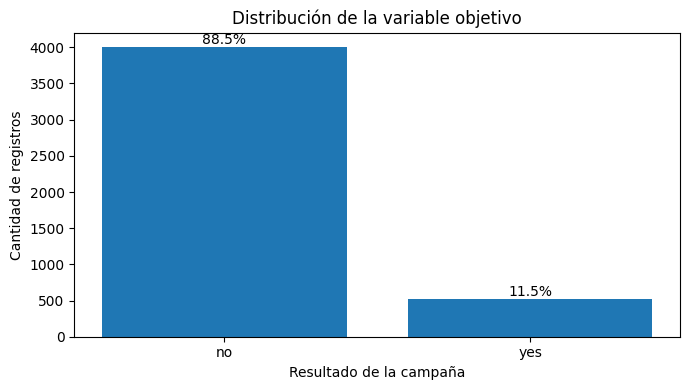

In [8]:

# Contar las observaciones de cada clase en Spark
distribucion_y = (
    bank_df
    .groupBy("y")
    .agg(F.count("*").alias("cantidad"))
    .withColumn(
        "porcentaje",
        F.col("cantidad") * 100 /
        F.sum("cantidad").over(Window.partitionBy())
    )
    .orderBy("y")
)

distribucion_y.show()

# Convertir únicamente la pequeña agregación a pandas
pdf_y = distribucion_y.toPandas()

etiquetas = pdf_y["y"].map({0: "no", 1: "yes"}).fillna("nulo")

plt.figure(figsize=(7, 4))
plt.bar(etiquetas, pdf_y["cantidad"])
plt.title("Distribución de la variable objetivo")
plt.xlabel("Resultado de la campaña")
plt.ylabel("Cantidad de registros")

for i, porcentaje in enumerate(pdf_y["porcentaje"]):
    plt.text(
        i,
        pdf_y["cantidad"].iloc[i],
        f"{porcentaje:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


### Distribución de las variables numéricas
Se grafican histogramas de `age`, `balance` y `campaign` para observar su forma y detectar valores atípicos. Los intervalos se calculan en Spark y solo la tabla de frecuencias se convierte a pandas.

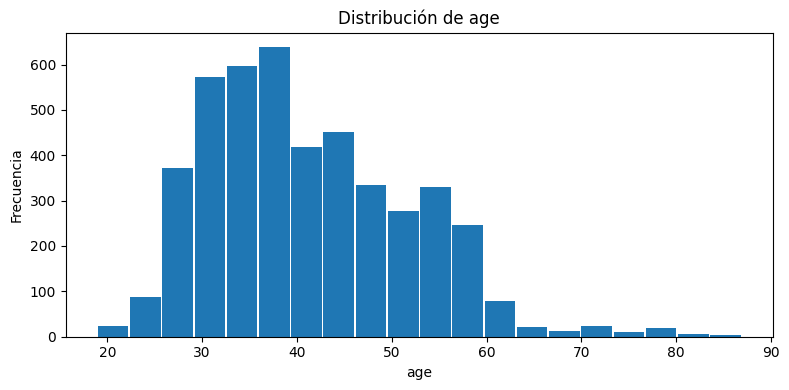

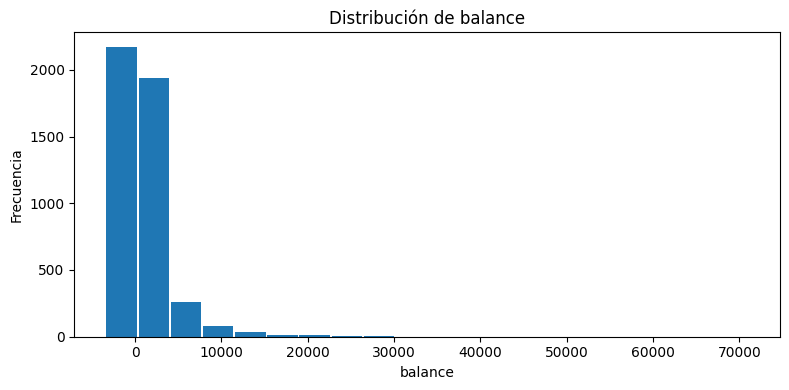

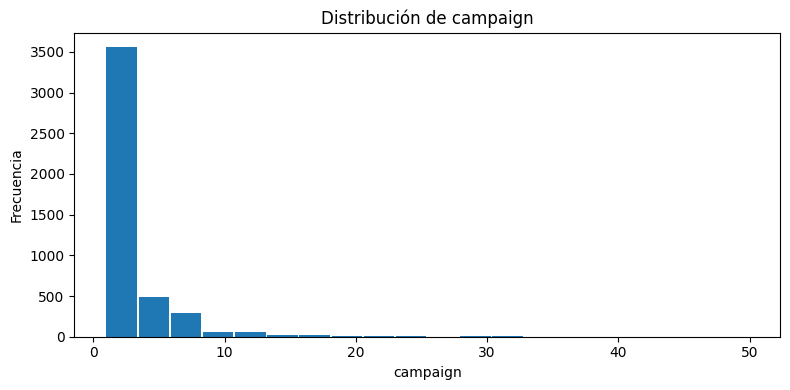

In [9]:

def calcular_histograma_spark(df, columna, numero_intervalos=20):
    # Obtener los límites de la variable en Spark
    limites = df.agg(
        F.min(columna).alias("minimo"),
        F.max(columna).alias("maximo")
    ).first()

    minimo = limites["minimo"]
    maximo = limites["maximo"]

    if minimo is None or maximo is None:
        print(f"No hay datos válidos para {columna}")
        return None

    if minimo == maximo:
        return pd.DataFrame({
            "intervalo": [f"{minimo}"],
            "frecuencia": [
                df.filter(F.col(columna).isNotNull()).count()
            ]
        })

    ancho = (maximo - minimo) / numero_intervalos

    # Asignar cada observación a un intervalo en Spark
    datos = (
        df.filter(F.col(columna).isNotNull())
        .withColumn(
            "intervalo_id",
            F.floor(
                (F.col(columna) - F.lit(minimo)) / F.lit(ancho)
            ).cast("integer")
        )
        .withColumn(
            "intervalo_id",
            F.least(
                F.col("intervalo_id"),
                F.lit(numero_intervalos - 1)
            )
        )
        .groupBy("intervalo_id")
        .agg(F.count("*").alias("frecuencia"))
        .orderBy("intervalo_id")
    )

    # Solo se convierte a pandas la tabla agregada
    pdf = datos.toPandas()

    pdf["limite_inferior"] = (
        minimo + pdf["intervalo_id"] * ancho
    )
    pdf["limite_superior"] = (
        pdf["limite_inferior"] + ancho
    )

    return pdf


for variable in ["age", "balance", "campaign"]:
    hist = calcular_histograma_spark(bank_df, variable)

    if hist is not None:
        plt.figure(figsize=(8, 4))

        plt.bar(
            hist["limite_inferior"],
            hist["frecuencia"],
            width=(
                hist["limite_superior"] -
                hist["limite_inferior"]
            ) * 0.95,
            align="edge"
        )

        plt.title(f"Distribución de {variable}")
        plt.xlabel(variable)
        plt.ylabel("Frecuencia")
        plt.tight_layout()
        plt.show()


### Correlación entre variables numéricas
Se calcula la matriz de correlación de Pearson entre las variables numéricas y la variable objetivo `y` usando Spark, y se visualiza como mapa de calor.

26/10/27 00:31:07 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
                                                                                

,age,balance,day,campaign,pdays,previous,y
age,1.000,0.084,-0.018,-0.005,-0.009,-0.004,0.045
balance,0.084,1.000,-0.009,-0.010,0.009,0.026,0.018
day,-0.018,-0.009,1.000,0.161,-0.094,-0.059,-0.011
campaign,-0.005,-0.010,0.161,1.000,-0.093,-0.068,-0.061
pdays,-0.009,0.009,-0.094,-0.093,1.000,0.577,0.104
previous,-0.004,0.026,-0.059,-0.068,0.577,1.000,0.117
y,0.045,0.018,-0.011,-0.061,0.104,0.117,1.000


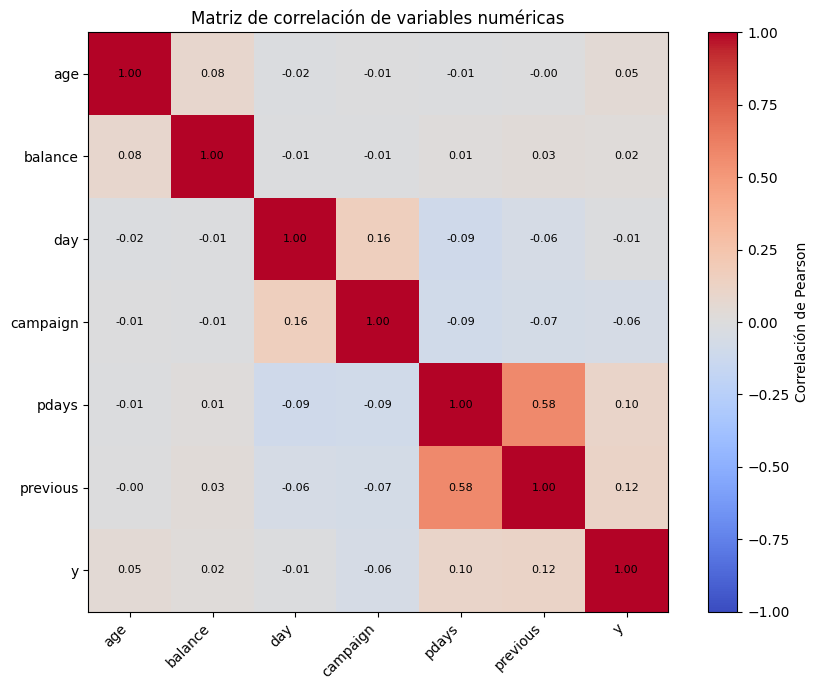

In [10]:
variables_correlacion = variables_numericas + ["y"]

# Excluir registros con valores nulos en las variables analizadas
df_correlacion = bank_df.select(
    *variables_correlacion
).na.drop()

# Construir el vector numérico en Spark
assembler = VectorAssembler(
    inputCols=variables_correlacion,
    outputCol="features"
)

datos_vectorizados = assembler.transform(df_correlacion)

# Calcular la matriz de correlación de Pearson en Spark
matriz_spark = Correlation.corr(
    datos_vectorizados,
    "features",
    "pearson"
).first()[0]

# La matriz es un resultado agregado pequeño
matriz = matriz_spark.toArray()

matriz_pdf = pd.DataFrame(
    matriz,
    index=variables_correlacion,
    columns=variables_correlacion
)

display(matriz_pdf.round(3))

# Visualizar la matriz sin requerir seaborn
fig, ax = plt.subplots(figsize=(9, 7))

imagen = ax.imshow(
    matriz,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(variables_correlacion)))
ax.set_xticklabels(variables_correlacion, rotation=45, ha="right")
ax.set_yticks(range(len(variables_correlacion)))
ax.set_yticklabels(variables_correlacion)

for i in range(len(variables_correlacion)):
    for j in range(len(variables_correlacion)):
        ax.text(
            j, i, f"{matriz[i, j]:.2f}",
            ha="center", va="center", fontsize=8
        )

fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()


### Relación de las variables categóricas con la variable objetivo
Para `job`, `month` y `poutcome` se calcula la tasa de `yes` por categoría y se grafica. Se incluye también un resumen con la categoría de mayor y menor tasa de cada variable.


Tasa de contratación por job:


+-------------+-----+------------+-------------------+------------------+
|job          |total|cantidad_yes|tasa_yes           |porcentaje_yes    |
+-------------+-----+------------+-------------------+------------------+
|retired      |230  |54          |0.23478260869565218|23.47826086956522 |
|student      |84   |19          |0.2261904761904762 |22.61904761904762 |
|unknown      |38   |7           |0.18421052631578946|18.421052631578945|
|management   |969  |131         |0.13519091847265222|13.519091847265221|
|housemaid    |112  |14          |0.125              |12.5              |
|admin.       |478  |58          |0.12133891213389121|12.133891213389122|
|self-employed|183  |20          |0.1092896174863388 |10.92896174863388 |
|technician   |768  |83          |0.10807291666666667|10.807291666666668|
|unemployed   |128  |13          |0.1015625          |10.15625          |
|services     |417  |38          |0.09112709832134293|9.112709832134293 |
|entrepreneur |168  |15          |0.08

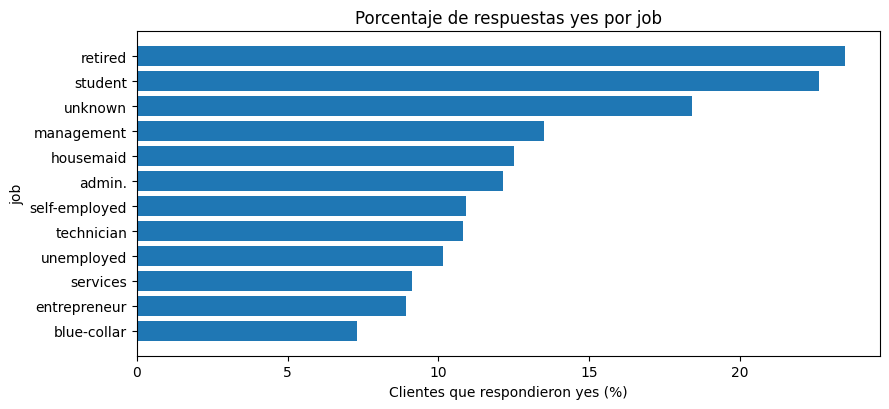


Tasa de contratación por month:


+-----+-----+------------+-------------------+------------------+
|month|total|cantidad_yes|tasa_yes           |porcentaje_yes    |
+-----+-----+------------+-------------------+------------------+
|oct  |80   |37          |0.4625             |46.25             |
|dec  |20   |9           |0.45               |45.0              |
|mar  |49   |21          |0.42857142857142855|42.857142857142854|
|sep  |52   |17          |0.3269230769230769 |32.69230769230769 |
|apr  |293  |56          |0.19112627986348124|19.112627986348123|
|feb  |222  |38          |0.17117117117117117|17.117117117117118|
|aug  |633  |79          |0.12480252764612954|12.480252764612953|
|jan  |148  |16          |0.10810810810810811|10.81081081081081 |
|jun  |531  |55          |0.10357815442561205|10.357815442561206|
|nov  |389  |39          |0.10025706940874037|10.025706940874036|
|jul  |706  |61          |0.08640226628895184|8.640226628895183 |
|may  |1398 |93          |0.06652360515021459|6.652360515021459 |
+-----+---

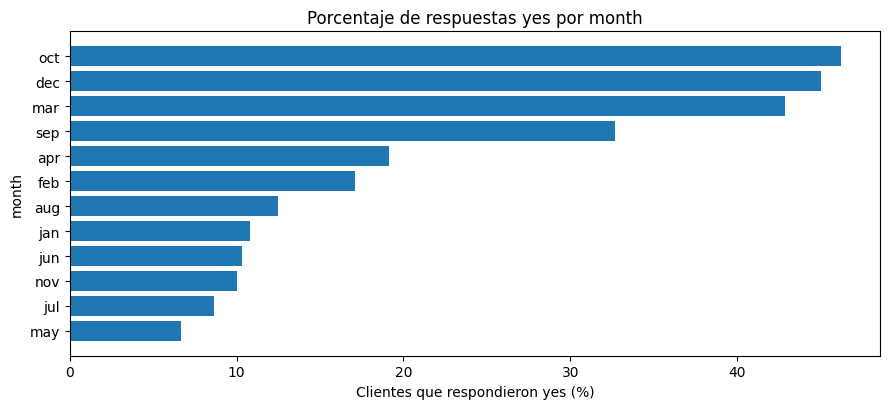


Tasa de contratación por poutcome:


+--------+-----+------------+-------------------+------------------+
|poutcome|total|cantidad_yes|tasa_yes           |porcentaje_yes    |
+--------+-----+------------+-------------------+------------------+
|success |129  |83          |0.6434108527131783 |64.34108527131784 |
|other   |197  |38          |0.19289340101522842|19.289340101522843|
|failure |490  |63          |0.12857142857142856|12.857142857142856|
|unknown |3705 |337         |0.09095816464237517|9.095816464237517 |
+--------+-----+------------+-------------------+------------------+



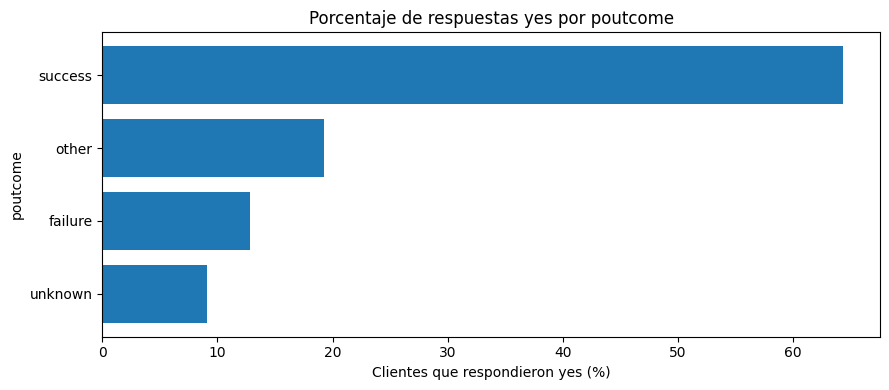

In [11]:

variables_categoricas = ["job", "month", "poutcome"]

def calcular_tasa_yes(df, variable):
    return (
        df.filter(F.col("y").isNotNull())
        .groupBy(variable)
        .agg(
            F.count("*").alias("total"),
            F.sum("y").alias("cantidad_yes"),
            F.avg("y").alias("tasa_yes")
        )
        .withColumn(
            "porcentaje_yes",
            F.col("tasa_yes") * 100
        )
        .orderBy(F.desc("porcentaje_yes"))
    )


resultados_categoricos = {}

for variable in variables_categoricas:
    tasas_spark = calcular_tasa_yes(bank_df, variable)

    print(f"\nTasa de contratación por {variable}:")
    tasas_spark.show(30, truncate=False)

    # Convertir únicamente las tasas agregadas
    tasas_pdf = tasas_spark.toPandas()
    resultados_categoricos[variable] = tasas_pdf

    # Gráfico ordenado de mayor a menor tasa
    tasas_pdf = tasas_pdf.sort_values(
        "porcentaje_yes", ascending=True
    )

    plt.figure(figsize=(9, max(4, len(tasas_pdf) * 0.35)))

    plt.barh(
        tasas_pdf[variable].astype(str),
        tasas_pdf["porcentaje_yes"]
    )

    plt.title(f"Porcentaje de respuestas yes por {variable}")
    plt.xlabel("Clientes que respondieron yes (%)")
    plt.ylabel(variable)
    plt.tight_layout()
    plt.show()


In [12]:

for variable, tasas in resultados_categoricos.items():
    tasas_validas = tasas.dropna(
        subset=["porcentaje_yes"]
    )

    if tasas_validas.empty:
        print(f"{variable}: no hay tasas disponibles.")
        continue

    mayor = tasas_validas.loc[
        tasas_validas["porcentaje_yes"].idxmax()
    ]
    menor = tasas_validas.loc[
        tasas_validas["porcentaje_yes"].idxmin()
    ]

    print(f"\nVariable: {variable}")
    print(
        f"Mayor tasa: {mayor[variable]} "
        f"({mayor['porcentaje_yes']:.2f} %, "
        f"n={int(mayor['total'])})"
    )
    print(
        f"Menor tasa: {menor[variable]} "
        f"({menor['porcentaje_yes']:.2f} %, "
        f"n={int(menor['total'])})"
    )



Variable: job
Mayor tasa: retired (23.48 %, n=230)
Menor tasa: blue-collar (7.29 %, n=946)

Variable: month
Mayor tasa: oct (46.25 %, n=80)
Menor tasa: may (6.65 %, n=1398)

Variable: poutcome
Mayor tasa: success (64.34 %, n=129)
Menor tasa: unknown (9.10 %, n=3705)


### Conclusiones del análisis exploratorio

1. **La variable objetivo está desbalanceada.** Solo el 11.5 % de los clientes (521 de 4 521) contrató el depósito. Un modelo que siempre respondiera "no" acertaría el 88.5 % de las veces, por lo que la exactitud (*accuracy*) por sí sola no sirve para evaluar los modelos. Se usan además AUC-ROC, F1 y la precisión y el recall de la clase `yes`.

2. **Las variables tienen escalas muy distintas y valores extremos.** Por ejemplo, `balance` tiene una media de 1 423 y un máximo de 71 188, mientras que `previous` tiene una media de 0.54. También hay valores muy altos en `campaign` (máximo 50) y `pdays` (máximo 871). Esto justifica estandarizar las variables numéricas antes de entrenar.

3. **La señal está en el historial de la campaña y en el perfil del cliente.** La tasa de contratación es de 64.3 % cuando el resultado de la campaña anterior fue `success`, frente a 9.1 % cuando es `unknown`. También es más alta en clientes jubilados (23.5 %) y estudiantes (22.6 %), y en los meses de octubre, diciembre y marzo, aunque estos meses tienen pocos registros. En cambio, las correlaciones lineales de las variables numéricas con `y` son débiles (la mayor es 0.117, con `previous`), lo que anticipa un desempeño limitado, ya que los datos aportan poca señal predictiva individual.

### Normalización y codificación de variables

**Normalización de las variables numéricas.** Se aplicó la estandarización Z-score a `age`, `balance`, `day`, `campaign`, `pdays` y `previous`, calculando la media y la desviación estándar con funciones de Spark. Esta estrategia expresa las variables en escalas comparables y resulta apropiada para modelos sensibles a las diferencias de magnitud. Se eligió frente a Min-Max por las diferencias de escala observadas en el análisis exploratorio y por la presencia de posibles valores extremos en `balance`. La variable `contactado_antes` se mantuvo sin cambios porque ya está codificada como 0/1.

**Codificación de variables categóricas.** Las variables binarias `credit_default`, `housing` y `loan` se transformaron a valores numéricos (1 para `yes` y 0 para `no`); en el conjunto de datos estas columnas solo contienen esos dos valores. Las variables `job`, `marital`, `education`, `contact`, `month` y `poutcome` se codificaron con One-Hot Encoding, generando una columna binaria por categoría excepto la categoría de referencia de cada variable (la primera en orden alfabético). Los valores `unknown` se mantienen como una categoría más. Esta representación evita el uso de vectores y permite almacenar los datos en PostgreSQL como columnas individuales. Los nombres de las columnas generadas se normalizaron para evitar caracteres problemáticos.

In [13]:

# Variables numéricas que se van a estandarizar
variables_numericas = [
    "age", "balance", "day",
    "campaign", "pdays", "previous"
]

# Calcular medias y desviaciones estándar en Spark
expresiones = []

for variable in variables_numericas:
    expresiones.append(F.mean(variable).alias(f"{variable}_mean"))
    expresiones.append(F.stddev(variable).alias(f"{variable}_std"))

estadisticas_zscore = bank_df.agg(*expresiones).first().asDict()

# Crear cada columna estandarizada
for variable in variables_numericas:
    media = estadisticas_zscore[f"{variable}_mean"]
    desviacion = estadisticas_zscore[f"{variable}_std"]

    if desviacion is None or desviacion == 0:
        # Si la variable no tiene variación, no se divide entre cero.
        bank_df = bank_df.withColumn(
            variable,
            F.lit(0.0)
        )
    else:
        bank_df = bank_df.withColumn(
            variable,
            (F.col(variable) - F.lit(media)) / F.lit(desviacion)
        )

# Verificar los resultados
bank_df.select(*variables_numericas).describe().show()


[Stage 205:===================================================> (194 + 4) / 200]

+-------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|summary|                 age|             balance|                 day|            campaign|               pdays|            previous|
+-------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+
|  count|                4521|                4521|                4521|                4521|                4521|                4521|
|   mean|-1.19985615976963...|-1.35554768766442...|1.738637251569588...|2.887905943285078...|-1.53235825562065...|8.840528397811466...|
| stddev|  1.0000000000000007|                 1.0|                 1.0|  0.9999999999999999|                 1.0|  0.9999999999999999|
|    min|  -2.096222853179778| -1.5734974089556901|  -1.808424568715274| -0.5767656719300787|-0.40672561694533865| -0.3203773839394116|
|    max|   4.333300939931663|  23.1806412859118

In [14]:
# Codificar las variables binarias
variables_binarias = ["credit_default", "housing", "loan"]

for variable in variables_binarias:
    valor = F.lower(F.trim(F.col(variable)))
    bank_df = bank_df.withColumn(
        variable,
        F.when(valor == "yes", 1)
         .when(valor == "no", 0)
         .otherwise(None)
         .cast("integer")
    )

# Comprobar la codificación
bank_df.select(*variables_binarias).show(10)


+--------------+-------+----+
|credit_default|housing|loan|
+--------------+-------+----+
|             0|      0|   0|
|             0|      0|   0|
|             0|      0|   1|
|             0|      0|   0|
|             0|      1|   1|
|             0|      1|   0|
|             0|      0|   1|
|             0|      0|   0|
|             0|      0|   0|
|             0|      1|   1|
+--------------+-------+----+
only showing top 10 rows



In [15]:
variables_categoricas = [
    "job", "marital", "education",
    "contact", "month", "poutcome"
]

# Normalizar nombres para que sean compatibles con PostgreSQL
def normalizar_nombre(texto):
    nombre = re.sub(r"[^a-zA-Z0-9]+", "_", str(texto))
    nombre = nombre.strip("_").lower()

    if not nombre:
        nombre = "categoria"

    if nombre[0].isdigit():
        nombre = "cat_" + nombre

    return nombre


columnas_onehot = []

for variable in variables_categoricas:

    # Tratar los nulos como una categoría explícita
    columna_temporal = f"__{variable}_categoria__"

    bank_df = bank_df.withColumn(
        columna_temporal,
        F.coalesce(
            F.col(variable).cast("string"),
            F.lit("__missing__")
        )
    )

    # Obtener las categorías distintas en Spark
    categorias = [
        fila["categoria"]
        for fila in (
            bank_df.select(
                F.col(columna_temporal).alias("categoria")
            )
            .distinct()
            .collect()
        )
    ]

    categorias = sorted(categorias)

    if not categorias:
        bank_df = bank_df.drop(columna_temporal)
        continue

    # Omitir la primera categoría como referencia
    categoria_referencia = categorias[0]

    print(
        f"{variable}: categoría de referencia = "
        f"{categoria_referencia}"
    )

    nombres_usados = set()

    for categoria in categorias[1:]:
        sufijo = normalizar_nombre(categoria)
        nombre_columna = f"{variable}_{sufijo}"

        # Evitar colisiones si dos categorías generan
        # el mismo nombre después de normalizarlo
        contador = 2
        while nombre_columna in nombres_usados:
            nombre_columna = f"{variable}_{sufijo}_{contador}"
            contador += 1

        nombres_usados.add(nombre_columna)

        bank_df = bank_df.withColumn(
            nombre_columna,
            F.when(
                F.col(columna_temporal) == categoria, 1
            ).otherwise(0).cast("integer")
        )

        columnas_onehot.append(nombre_columna)

    # Eliminar la columna temporal
    bank_df = bank_df.drop(columna_temporal)

print("Cantidad de columnas One-Hot creadas:", len(columnas_onehot))
print("Columnas generadas:")
print(columnas_onehot)


job: categoría de referencia = admin.


marital: categoría de referencia = divorced


education: categoría de referencia = primary


contact: categoría de referencia = cellular


month: categoría de referencia = apr


[Stage 237:=====================================>               (140 + 4) / 200]

poutcome: categoría de referencia = failure
Cantidad de columnas One-Hot creadas: 32
Columnas generadas:
['job_blue_collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self_employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_married', 'marital_single', 'education_secondary', 'education_tertiary', 'education_unknown', 'contact_telephone', 'contact_unknown', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']


In [16]:

# Mostrar el esquema resultante
bank_df.printSchema()

# Comprobar las variables binarias y contactado_antes
columnas_verificacion = [
    "credit_default", "housing", "loan",
    "contactado_antes", "y"
]

bank_df.select(*columnas_verificacion).show(10)

# Mostrar algunas columnas One-Hot
columnas_muestra = (
    variables_categoricas[:2]
)

columnas_muestra_onehot = [
    c for c in columnas_onehot
    if any(c.startswith(v + "_") for v in columnas_muestra)
][:10]

bank_df.select(
    *variables_categoricas[:2],
    *columnas_muestra_onehot
).show(10, truncate=False)

# Verificar el número de filas y columnas
print("Número de registros:", bank_df.count())
print("Número de columnas:", len(bank_df.columns))

# Comprobar que no se hayan creado nombres duplicados
assert len(bank_df.columns) == len(set(bank_df.columns)), \
    "Hay nombres de columnas duplicados."

# Comprobar que las columnas que debían eliminarse ya no existen
assert "duration" not in bank_df.columns
assert "default" not in bank_df.columns

# Comprobar que contactado_antes se mantiene intacta
print("Distribución de contactado_antes:")
bank_df.groupBy("contactado_antes").count().show()

print("Preparación de variables completada.")


root
 |-- age: double (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- credit_default: integer (nullable = true)
 |-- balance: double (nullable = true)
 |-- housing: integer (nullable = true)
 |-- loan: integer (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: double (nullable = true)
 |-- month: string (nullable = true)
 |-- campaign: double (nullable = true)
 |-- pdays: double (nullable = true)
 |-- previous: double (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: integer (nullable = true)
 |-- contactado_antes: integer (nullable = false)
 |-- job_blue_collar: integer (nullable = false)
 |-- job_entrepreneur: integer (nullable = false)
 |-- job_housemaid: integer (nullable = false)
 |-- job_management: integer (nullable = false)
 |-- job_retired: integer (nullable = false)
 |-- job_self_employed: integer (nullable = false)
 |-- job_services: integer (nullable = f

Número de registros: 4521
Número de columnas: 49
Distribución de contactado_antes:


[Stage 251:==================================================>  (192 + 5) / 200]

+----------------+-----+
|contactado_antes|count|
+----------------+-----+
|               1|  816|
|               0| 3705|
+----------------+-----+

Preparación de variables completada.


In [17]:
# Eliminar las columnas categóricas originales; ya están codificadas
bank_df = bank_df.drop(*variables_categoricas)

assert all(v not in bank_df.columns for v in variables_categoricas)
print("Columnas finales:", len(bank_df.columns))
bank_df.printSchema()

Columnas finales: 43
root
 |-- age: double (nullable = true)
 |-- credit_default: integer (nullable = true)
 |-- balance: double (nullable = true)
 |-- housing: integer (nullable = true)
 |-- loan: integer (nullable = true)
 |-- day: double (nullable = true)
 |-- campaign: double (nullable = true)
 |-- pdays: double (nullable = true)
 |-- previous: double (nullable = true)
 |-- y: integer (nullable = true)
 |-- contactado_antes: integer (nullable = false)
 |-- job_blue_collar: integer (nullable = false)
 |-- job_entrepreneur: integer (nullable = false)
 |-- job_housemaid: integer (nullable = false)
 |-- job_management: integer (nullable = false)
 |-- job_retired: integer (nullable = false)
 |-- job_self_employed: integer (nullable = false)
 |-- job_services: integer (nullable = false)
 |-- job_student: integer (nullable = false)
 |-- job_technician: integer (nullable = false)
 |-- job_unemployed: integer (nullable = false)
 |-- job_unknown: integer (nullable = false)
 |-- marital_marri

### Escritura de la tabla `tarea3` en PostgreSQL

Una vez depurados, normalizados y codificados los datos, se escribe el conjunto resultante en la tabla `tarea3` de la base de datos PostgreSQL, usando el modo `overwrite` para que la escritura se pueda repetir sin duplicar registros. Todas las columnas se almacenan de forma individual (numéricas estandarizadas, binarias y columnas One-Hot), sin vectores.

Para comprobar la escritura, la tabla se lee de vuelta desde PostgreSQL y se verifica el número de registros, el número de columnas y los tipos de dato. También se puede inspeccionar directamente desde la terminal:

```
docker exec -it postgres psql -U spark -d tarea3db -c "\d tarea3"
docker exec -it postgres psql -U spark -d tarea3db -c "SELECT COUNT(*) FROM tarea3;"
```

In [18]:
# Escribir el conjunto de datos depurado en PostgreSQL
bank_df.write.jdbc(
    url=jdbc_url,
    table="tarea3",
    mode="overwrite",
    properties=jdbc_props
)

# Leer la tabla de vuelta para comprobar que se escribió bien
tarea3_df = spark.read.jdbc(
    url=jdbc_url,
    table="tarea3",
    properties=jdbc_props
)

print("Registros en PostgreSQL:", tarea3_df.count())
print("Columnas en PostgreSQL:", len(tarea3_df.columns))
tarea3_df.printSchema()
tarea3_df.show(5)

# Comprobar que coincide con el DataFrame original y que no hay vectores
assert tarea3_df.count() == bank_df.count()
assert len(tarea3_df.columns) == len(bank_df.columns)
assert not any("vector" in tipo.lower() for _, tipo in tarea3_df.dtypes)
print("Escritura verificada.")

Registros en PostgreSQL: 4521
Columnas en PostgreSQL: 43
root
 |-- age: double (nullable = true)
 |-- credit_default: integer (nullable = true)
 |-- balance: double (nullable = true)
 |-- housing: integer (nullable = true)
 |-- loan: integer (nullable = true)
 |-- day: double (nullable = true)
 |-- campaign: double (nullable = true)
 |-- pdays: double (nullable = true)
 |-- previous: double (nullable = true)
 |-- y: integer (nullable = true)
 |-- contactado_antes: integer (nullable = true)
 |-- job_blue_collar: integer (nullable = true)
 |-- job_entrepreneur: integer (nullable = true)
 |-- job_housemaid: integer (nullable = true)
 |-- job_management: integer (nullable = true)
 |-- job_retired: integer (nullable = true)
 |-- job_self_employed: integer (nullable = true)
 |-- job_services: integer (nullable = true)
 |-- job_student: integer (nullable = true)
 |-- job_technician: integer (nullable = true)
 |-- job_unemployed: integer (nullable = true)
 |-- job_unknown: integer (nullable = 

[Stage 265:================================================>    (184 + 4) / 200]

Escritura verificada.


## Entrenamiento de modelos

### Protocolo
1. Se carga desde PostgreSQL la tabla `tarea3` (datos ya depurados y normalizados).
2. Se separa un **conjunto de validación final** (20 %) que no se usa durante el entrenamiento ni la selección de hiperparámetros. El 80 % restante es el conjunto de entrenamiento. La separación usa una semilla fija para que sea reproducible.
3. Se entrenan **dos modelos de clasificación** con **K-Fold Cross Validation** (`CrossValidator` de Spark, 3 folds) sobre el conjunto de entrenamiento, buscando los mejores hiperparámetros con `ParamGridBuilder`.
4. La métrica de selección es el **área bajo la curva ROC (AUC)**, apropiada para un conjunto desbalanceado (11.5 % de `yes`).
5. Se reportan las métricas del mejor modelo de cada tipo sobre el conjunto de entrenamiento. La evaluación sobre el conjunto de validación se presenta en la sección siguiente.

### Modelos seleccionados
- **Modelo 1: Regresión logística.** Modelo lineal simple e interpretable; sirve como línea base. Se ajustan `regParam` y `elasticNetParam`.
- **Modelo 2: Random Forest.** Modelo de ensamble de árboles que captura relaciones no lineales e interacciones entre variables. Se ajustan `numTrees` y `maxDepth`.

### Carga de los datos desde PostgreSQL
Se lee la tabla `tarea3` desde la base de datos y se verifica que la etiqueta `y` sea binaria y no tenga nulos. El DataFrame se deja en caché para que la partición posterior sea consistente.

In [19]:
# Cargar desde PostgreSQL el conjunto de datos depurado
df = spark.read.jdbc(
    url=jdbc_url,
    table="tarea3",
    properties=jdbc_props
).cache()

print("Registros:", df.count())
print("Columnas:", len(df.columns))
df.printSchema()
df.show(3)

# Verificar que la etiqueta sea binaria y no tenga nulos
etiquetas_invalidas = df.filter(
    F.col("y").isNull() | (~F.col("y").isin(0, 1))
).count()

if etiquetas_invalidas > 0:
    raise ValueError(
        f"Se encontraron {etiquetas_invalidas} etiquetas nulas o inválidas."
    )

print("Etiqueta y válida: solo contiene 0 y 1, sin nulos.")

Registros: 4521
Columnas: 43
root
 |-- age: double (nullable = true)
 |-- credit_default: integer (nullable = true)
 |-- balance: double (nullable = true)
 |-- housing: integer (nullable = true)
 |-- loan: integer (nullable = true)
 |-- day: double (nullable = true)
 |-- campaign: double (nullable = true)
 |-- pdays: double (nullable = true)
 |-- previous: double (nullable = true)
 |-- y: integer (nullable = true)
 |-- contactado_antes: integer (nullable = true)
 |-- job_blue_collar: integer (nullable = true)
 |-- job_entrepreneur: integer (nullable = true)
 |-- job_housemaid: integer (nullable = true)
 |-- job_management: integer (nullable = true)
 |-- job_retired: integer (nullable = true)
 |-- job_self_employed: integer (nullable = true)
 |-- job_services: integer (nullable = true)
 |-- job_student: integer (nullable = true)
 |-- job_technician: integer (nullable = true)
 |-- job_unemployed: integer (nullable = true)
 |-- job_unknown: integer (nullable = true)
 |-- marital_married: 

### Partición en entrenamiento y validación final
Se reserva el 20 % de los datos como conjunto de validación final. Este conjunto no participa en el entrenamiento ni en la validación cruzada; se usa únicamente para la evaluación final de los modelos.

In [20]:
# Partición 80 % entrenamiento, 20 % validación final
train_df, validacion_final_df = df.randomSplit([0.8, 0.2], seed=42)

train_df = train_df.cache()
validacion_final_df = validacion_final_df.cache()

print("Registros de entrenamiento:", train_df.count())
print("Registros de validación final:", validacion_final_df.count())

print("Distribución de y en entrenamiento:")
train_df.groupBy("y").count().orderBy("y").show()

print("Distribución de y en validación final:")
validacion_final_df.groupBy("y").count().orderBy("y").show()

[Stage 277:>                                                        (0 + 1) / 1]

Registros de entrenamiento: 3662


Registros de validación final: 859
Distribución de y en entrenamiento:
+---+-----+
|  y|count|
+---+-----+
|  0| 3240|
|  1|  422|
+---+-----+

Distribución de y en validación final:
+---+-----+
|  y|count|
+---+-----+
|  0|  760|
|  1|   99|
+---+-----+



### Selección de características
Las características del modelo son todas las columnas numéricas de la tabla excepto la etiqueta `y`. Se ensamblan en un único vector (`features`) dentro del pipeline de Spark; este vector no se guarda en la base de datos.

In [21]:
tipos_numericos = (
    ByteType, ShortType, IntegerType, LongType,
    FloatType, DoubleType, DecimalType
)

# Seleccionar todas las columnas numéricas excepto la etiqueta
columnas_features = [
    campo.name
    for campo in df.schema.fields
    if isinstance(campo.dataType, tipos_numericos)
    and campo.name != "y"
]

if not columnas_features:
    raise ValueError("No se encontraron columnas numéricas para entrenar.")

print("Cantidad de características:", len(columnas_features))
print("Características:", columnas_features)

ensamblador = VectorAssembler(
    inputCols=columnas_features,
    outputCol="features",
    handleInvalid="error"
)

Cantidad de características: 42
Características: ['age', 'credit_default', 'balance', 'housing', 'loan', 'day', 'campaign', 'pdays', 'previous', 'contactado_antes', 'job_blue_collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self_employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_married', 'marital_single', 'education_secondary', 'education_tertiary', 'education_unknown', 'contact_telephone', 'contact_unknown', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']


### Modelo 1: Regresión logística
Se entrena una regresión logística dentro de un pipeline (ensamblador de características + clasificador). Los hiperparámetros `regParam` (intensidad de la regularización) y `elasticNetParam` (mezcla entre regularización L1 y L2) se seleccionan con validación cruzada de 3 folds, usando el AUC-ROC como métrica.

In [22]:
# Evaluadores
evaluador_auc = BinaryClassificationEvaluator(
    labelCol="y",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

evaluador_mc = MulticlassClassificationEvaluator(
    labelCol="y",
    predictionCol="prediction"
)

# Clasificador
lr = LogisticRegression(
    labelCol="y",
    featuresCol="features",
    maxIter=100
)

pipeline_lr = Pipeline(stages=[ensamblador, lr])

# Espacio de búsqueda
grid_lr = (
    ParamGridBuilder()
    .addGrid(lr.regParam, [0.01, 0.1, 1.0])
    .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])
    .build()
)

cv_lr = CrossValidator(
    estimator=pipeline_lr,
    estimatorParamMaps=grid_lr,
    evaluator=evaluador_auc,
    numFolds=3,
    seed=42,
    parallelism=2
)

# Entrenar y seleccionar el mejor modelo usando solo train_df
modelo_lr_cv = cv_lr.fit(train_df)

print("AUC-ROC promedio de cada combinación (3 folds):")
for params, auc in zip(grid_lr, modelo_lr_cv.avgMetrics):
    print({p.name: v for p, v in params.items()}, round(auc, 4))

print(
    "\nMejor AUC-ROC promedio en validación cruzada:",
    round(max(modelo_lr_cv.avgMetrics), 4)
)

AUC-ROC promedio de cada combinación (3 folds):
{'regParam': 0.01, 'elasticNetParam': 0.0} 0.7165
{'regParam': 0.01, 'elasticNetParam': 0.5} 0.7185
{'regParam': 0.01, 'elasticNetParam': 1.0} 0.7133
{'regParam': 0.1, 'elasticNetParam': 0.0} 0.7171
{'regParam': 0.1, 'elasticNetParam': 0.5} 0.5729
{'regParam': 0.1, 'elasticNetParam': 1.0} 0.5
{'regParam': 1.0, 'elasticNetParam': 0.0} 0.7072
{'regParam': 1.0, 'elasticNetParam': 0.5} 0.5
{'regParam': 1.0, 'elasticNetParam': 1.0} 0.5

Mejor AUC-ROC promedio en validación cruzada: 0.7185


### Modelo 2: Random Forest
Se entrena un Random Forest con el mismo protocolo: pipeline, validación cruzada de 3 folds y AUC-ROC como métrica de selección. Los hiperparámetros ajustados son `numTrees` (cantidad de árboles) y `maxDepth` (profundidad máxima de cada árbol).

In [23]:
rf = RandomForestClassifier(
    labelCol="y",
    featuresCol="features",
    seed=42
)

pipeline_rf = Pipeline(stages=[ensamblador, rf])

grid_rf = (
    ParamGridBuilder()
    .addGrid(rf.numTrees, [50, 100])
    .addGrid(rf.maxDepth, [5, 10])
    .build()
)

cv_rf = CrossValidator(
    estimator=pipeline_rf,
    estimatorParamMaps=grid_rf,
    evaluator=evaluador_auc,
    numFolds=3,
    seed=42,
    parallelism=2
)

# Entrenar y seleccionar el mejor modelo usando solo train_df
modelo_rf_cv = cv_rf.fit(train_df)

print("AUC-ROC promedio de cada combinación (3 folds):")
for params, auc in zip(grid_rf, modelo_rf_cv.avgMetrics):
    print({p.name: v for p, v in params.items()}, round(auc, 4))

print(
    "\nMejor AUC-ROC promedio en validación cruzada:",
    round(max(modelo_rf_cv.avgMetrics), 4)
)

26/10/27 00:33:45 WARN DAGScheduler: Broadcasting large task binary with size 1103.9 KiB
26/10/27 00:33:46 WARN DAGScheduler: Broadcasting large task binary with size 1357.4 KiB
26/10/27 00:33:51 WARN DAGScheduler: Broadcasting large task binary with size 1123.9 KiB
26/10/27 00:33:52 WARN DAGScheduler: Broadcasting large task binary with size 1536.6 KiB
26/10/27 00:33:52 WARN DAGScheduler: Broadcasting large task binary with size 2006.9 KiB
26/10/27 00:33:53 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB
26/10/27 00:33:54 WARN DAGScheduler: Broadcasting large task binary with size 1607.8 KiB
26/10/27 00:33:57 WARN DAGScheduler: Broadcasting large task binary with size 1048.1 KiB
26/10/27 00:33:58 WARN DAGScheduler: Broadcasting large task binary with size 1288.1 KiB
26/10/27 00:34:18 WARN DAGScheduler: Broadcasting large task binary with size 1106.4 KiB
26/10/27 00:34:18 WARN DAGScheduler: Broadcasting large task binary with size 1504.4 KiB
26/10/27 00:34:20 WARN D

AUC-ROC promedio de cada combinación (3 folds):
{'numTrees': 50, 'maxDepth': 5} 0.731
{'numTrees': 50, 'maxDepth': 10} 0.7317
{'numTrees': 100, 'maxDepth': 5} 0.7249
{'numTrees': 100, 'maxDepth': 10} 0.733

Mejor AUC-ROC promedio en validación cruzada: 0.733


### Métricas sobre el conjunto de entrenamiento
Para el mejor modelo de cada tipo se calculan las métricas sobre el conjunto de entrenamiento: AUC-ROC, exactitud (*accuracy*), F1 ponderado y la precisión y el recall de la clase positiva (`yes`), junto con la matriz de confusión. Como la clase positiva es minoritaria, la precisión y el recall de `yes` son más informativos que la exactitud global.

In [24]:
# Obtener los mejores modelos seleccionados
mejor_lr = modelo_lr_cv.bestModel
mejor_rf = modelo_rf_cv.bestModel

clasificador_lr = mejor_lr.stages[-1]
clasificador_rf = mejor_rf.stages[-1]

# Predicciones sobre entrenamiento
pred_lr_train = mejor_lr.transform(train_df)
pred_rf_train = mejor_rf.transform(train_df)


def metricas_clasificacion(pred):
    return {
        "AUC-ROC": evaluador_auc.evaluate(pred),
        "Accuracy": evaluador_mc.setMetricName("accuracy").evaluate(pred),
        "F1 (ponderado)": evaluador_mc.setMetricName("f1").evaluate(pred),
        "Precisión (yes)": evaluador_mc.setMetricName(
            "precisionByLabel").setMetricLabel(1.0).evaluate(pred),
        "Recall (yes)": evaluador_mc.setMetricName(
            "recallByLabel").setMetricLabel(1.0).evaluate(pred),
    }


metricas_lr_train = metricas_clasificacion(pred_lr_train)
metricas_rf_train = metricas_clasificacion(pred_rf_train)

print("===== REGRESIÓN LOGÍSTICA =====")
print("regParam:", clasificador_lr.getRegParam())
print("elasticNetParam:", clasificador_lr.getElasticNetParam())
for nombre, valor in metricas_lr_train.items():
    print(f"{nombre}: {valor:.4f}")
print("Matriz de confusión (entrenamiento):")
pred_lr_train.groupBy("y", "prediction").count() \
    .orderBy("y", "prediction").show()

print("\n===== RANDOM FOREST =====")
print("numTrees:", clasificador_rf.getNumTrees)
print("maxDepth:", clasificador_rf.getOrDefault(clasificador_rf.maxDepth))
for nombre, valor in metricas_rf_train.items():
    print(f"{nombre}: {valor:.4f}")
print("Matriz de confusión (entrenamiento):")
pred_rf_train.groupBy("y", "prediction").count() \
    .orderBy("y", "prediction").show()

26/10/27 00:35:10 WARN DAGScheduler: Broadcasting large task binary with size 1810.2 KiB
26/10/27 00:35:11 WARN DAGScheduler: Broadcasting large task binary with size 1822.7 KiB
26/10/27 00:35:12 WARN DAGScheduler: Broadcasting large task binary with size 1822.7 KiB
26/10/27 00:35:13 WARN DAGScheduler: Broadcasting large task binary with size 1822.7 KiB
26/10/27 00:35:14 WARN DAGScheduler: Broadcasting large task binary with size 1822.7 KiB


===== REGRESIÓN LOGÍSTICA =====
regParam: 0.01
elasticNetParam: 0.5
AUC-ROC: 0.7435
Accuracy: 0.8919
F1 (ponderado): 0.8591
Precisión (yes): 0.6477
Recall (yes): 0.1351
Matriz de confusión (entrenamiento):
+---+----------+-----+
|  y|prediction|count|
+---+----------+-----+
|  0|       0.0| 3209|
|  0|       1.0|   31|
|  1|       0.0|  365|
|  1|       1.0|   57|
+---+----------+-----+


===== RANDOM FOREST =====
numTrees: 100
maxDepth: 10
AUC-ROC: 0.9218
Accuracy: 0.9143
F1 (ponderado): 0.8908
Precisión (yes): 1.0000
Recall (yes): 0.2559
Matriz de confusión (entrenamiento):


26/10/27 00:35:16 WARN DAGScheduler: Broadcasting large task binary with size 1819.6 KiB


+---+----------+-----+
|  y|prediction|count|
+---+----------+-----+
|  0|       0.0| 3240|
|  1|       0.0|  314|
|  1|       1.0|  108|
+---+----------+-----+



26/10/27 00:35:16 WARN DAGScheduler: Broadcasting large task binary with size 1785.6 KiB


In [25]:
resumen_modelos = pd.DataFrame([
    {
        "Modelo": "Regresión logística",
        "AUC-ROC CV": max(modelo_lr_cv.avgMetrics),
        **metricas_lr_train,
        "Hiperparámetros": (
            f"regParam={clasificador_lr.getRegParam()}, "
            f"elasticNetParam={clasificador_lr.getElasticNetParam()}"
        )
    },
    {
        "Modelo": "Random Forest",
        "AUC-ROC CV": max(modelo_rf_cv.avgMetrics),
        **metricas_rf_train,
        "Hiperparámetros": (
            f"numTrees={clasificador_rf.getNumTrees}, "
            f"maxDepth={clasificador_rf.getOrDefault(clasificador_rf.maxDepth)}"
        )
    }
])

display(resumen_modelos.round(4))

,Modelo,AUC-ROC CV,AUC-ROC,Accuracy,F1 (ponderado),Precisión (yes),Recall (yes),Hiperparámetros
0,Regresión logística,0.7185,0.7435,0.8919,0.8591,0.6477,0.1351,"regParam=0.01, elasticNetParam=0.5"
1,Random Forest,0.7330,0.9218,0.9143,0.8908,1.0000,0.2559,"numTrees=100, maxDepth=10"


**Observaciones sobre el entrenamiento:**

- **Regresión logística:** la validación cruzada eligió `regParam=0.01` y `elasticNetParam=0.5`, con un AUC-ROC promedio de 0.7185. Con regularización más fuerte combinada con L1 (regParam de 0.1 o mayor con elasticNetParam de 0.5 o 1.0) el AUC cae a valores entre 0.5 y 0.57, porque el modelo anula total o casi totalmente los coeficientes y deja de discriminar.
- **Random Forest:** eligió 100 árboles con profundidad máxima 10, con un AUC-ROC promedio de 0.733. Las cuatro combinaciones probadas quedaron entre 0.725 y 0.733, por lo que el ajuste de estos hiperparámetros tuvo poco efecto.
- **Entrenamiento frente a validación cruzada:** la regresión logística muestra una diferencia pequeña (0.7435 en entrenamiento frente a 0.7185 en validación cruzada). El Random Forest muestra una diferencia grande (0.9218 frente a 0.733), con precisión de 1.0 en entrenamiento, lo que indica **sobreajuste**: el modelo memoriza el conjunto de entrenamiento.
- **Recall de la clase `yes`:** es bajo en ambos modelos (13.5 % en la regresión logística y 25.6 % en el Random Forest). Por el desbalance de clases, con el umbral por defecto de 0.5 los modelos clasifican casi todo como `no`.

## Evaluación sobre el conjunto de validación final

Cada mejor modelo se evalúa sobre el conjunto de validación final, que no se usó en el entrenamiento ni en la validación cruzada. Se calculan las mismas métricas que en entrenamiento, para poder comparar y detectar sobreajuste, y se muestra la matriz de confusión.

In [26]:
# Predicciones de cada mejor modelo sobre la validación final
pred_lr_val = mejor_lr.transform(validacion_final_df)
pred_rf_val = mejor_rf.transform(validacion_final_df)

metricas_lr_val = metricas_clasificacion(pred_lr_val)
metricas_rf_val = metricas_clasificacion(pred_rf_val)

for nombre, metricas, pred in [
    ("REGRESIÓN LOGÍSTICA", metricas_lr_val, pred_lr_val),
    ("RANDOM FOREST", metricas_rf_val, pred_rf_val),
]:
    print(f"===== {nombre} (validación final) =====")
    for metrica, valor in metricas.items():
        print(f"{metrica}: {valor:.4f}")
    print("Matriz de confusión (validación final):")
    pred.groupBy("y", "prediction").count() \
        .orderBy("y", "prediction").show()

# Comparación entrenamiento vs validación
comparacion = pd.DataFrame([
    {"Modelo": "Regresión logística", "Conjunto": "Entrenamiento", **metricas_lr_train},
    {"Modelo": "Regresión logística", "Conjunto": "Validación final", **metricas_lr_val},
    {"Modelo": "Random Forest", "Conjunto": "Entrenamiento", **metricas_rf_train},
    {"Modelo": "Random Forest", "Conjunto": "Validación final", **metricas_rf_val},
])

display(comparacion.round(4))

26/10/27 00:35:18 WARN DAGScheduler: Broadcasting large task binary with size 1810.2 KiB
26/10/27 00:35:18 WARN DAGScheduler: Broadcasting large task binary with size 1822.7 KiB
26/10/27 00:35:18 WARN DAGScheduler: Broadcasting large task binary with size 1822.7 KiB
26/10/27 00:35:19 WARN DAGScheduler: Broadcasting large task binary with size 1822.7 KiB
26/10/27 00:35:19 WARN DAGScheduler: Broadcasting large task binary with size 1822.7 KiB


===== REGRESIÓN LOGÍSTICA (validación final) =====
AUC-ROC: 0.7516
Accuracy: 0.8976
F1 (ponderado): 0.8654
Precisión (yes): 0.7895
Recall (yes): 0.1515
Matriz de confusión (validación final):
+---+----------+-----+
|  y|prediction|count|
+---+----------+-----+
|  0|       0.0|  756|
|  0|       1.0|    4|
|  1|       0.0|   84|
|  1|       1.0|   15|
+---+----------+-----+

===== RANDOM FOREST (validación final) =====
AUC-ROC: 0.7670
Accuracy: 0.8894
F1 (ponderado): 0.8507
Precisión (yes): 0.6429
Recall (yes): 0.0909
Matriz de confusión (validación final):


26/10/27 00:35:19 WARN DAGScheduler: Broadcasting large task binary with size 1819.6 KiB


+---+----------+-----+
|  y|prediction|count|
+---+----------+-----+
|  0|       0.0|  755|
|  0|       1.0|    5|
|  1|       0.0|   90|
|  1|       1.0|    9|
+---+----------+-----+



26/10/27 00:35:20 WARN DAGScheduler: Broadcasting large task binary with size 1785.6 KiB


,Modelo,Conjunto,AUC-ROC,Accuracy,F1 (ponderado),Precisión (yes),Recall (yes)
0,Regresión logística,Entrenamiento,0.7435,0.8919,0.8591,0.6477,0.1351
1,Regresión logística,Validación final,0.7516,0.8976,0.8654,0.7895,0.1515
2,Random Forest,Entrenamiento,0.9218,0.9143,0.8908,1.0000,0.2559
3,Random Forest,Validación final,0.7670,0.8894,0.8507,0.6429,0.0909


### Almacenamiento de las predicciones en PostgreSQL

Para cada modelo se escribe una tabla con las predicciones sobre el conjunto de validación final: `modelo1` (regresión logística) y `modelo2` (Random Forest), ambas con modo `overwrite`. Cada tabla contiene las mismas columnas que `tarea3` más la columna `prediccion` con el resultado predicho (0 o 1). No se guardan vectores: las columnas intermedias del pipeline (`features`, `rawPrediction` y `probability`) se descartan antes de escribir. Después de escribir, cada tabla se lee de vuelta para verificarla.

In [27]:
def guardar_predicciones(pred, tabla):
    # Mismas columnas que tarea3 + prediccion (sin vectores)
    salida = pred.select(
        *df.columns,
        F.col("prediction").cast("integer").alias("prediccion")
    )

    salida.write.jdbc(
        url=jdbc_url,
        table=tabla,
        mode="overwrite",
        properties=jdbc_props
    )

    # Leer de vuelta para verificar
    leida = spark.read.jdbc(
        url=jdbc_url,
        table=tabla,
        properties=jdbc_props
    )

    print(f"===== Tabla {tabla} =====")
    print("Registros:", leida.count())
    print("Columnas:", len(leida.columns))
    leida.printSchema()
    leida.show(5)

    assert leida.count() == validacion_final_df.count()
    assert leida.columns == df.columns + ["prediccion"]
    assert not any("vector" in t.lower() for _, t in leida.dtypes)
    print(f"Tabla {tabla} verificada.\n")


guardar_predicciones(pred_lr_val, "modelo1")
guardar_predicciones(pred_rf_val, "modelo2")

===== Tabla modelo1 =====
Registros: 859
Columnas: 44
root
 |-- age: double (nullable = true)
 |-- credit_default: integer (nullable = true)
 |-- balance: double (nullable = true)
 |-- housing: integer (nullable = true)
 |-- loan: integer (nullable = true)
 |-- day: double (nullable = true)
 |-- campaign: double (nullable = true)
 |-- pdays: double (nullable = true)
 |-- previous: double (nullable = true)
 |-- y: integer (nullable = true)
 |-- contactado_antes: integer (nullable = true)
 |-- job_blue_collar: integer (nullable = true)
 |-- job_entrepreneur: integer (nullable = true)
 |-- job_housemaid: integer (nullable = true)
 |-- job_management: integer (nullable = true)
 |-- job_retired: integer (nullable = true)
 |-- job_self_employed: integer (nullable = true)
 |-- job_services: integer (nullable = true)
 |-- job_student: integer (nullable = true)
 |-- job_technician: integer (nullable = true)
 |-- job_unemployed: integer (nullable = true)
 |-- job_unknown: integer (nullable = tru

26/10/27 00:35:22 WARN DAGScheduler: Broadcasting large task binary with size 1824.6 KiB
                                                                                

===== Tabla modelo2 =====
Registros: 859
Columnas: 44
root
 |-- age: double (nullable = true)
 |-- credit_default: integer (nullable = true)
 |-- balance: double (nullable = true)
 |-- housing: integer (nullable = true)
 |-- loan: integer (nullable = true)
 |-- day: double (nullable = true)
 |-- campaign: double (nullable = true)
 |-- pdays: double (nullable = true)
 |-- previous: double (nullable = true)
 |-- y: integer (nullable = true)
 |-- contactado_antes: integer (nullable = true)
 |-- job_blue_collar: integer (nullable = true)
 |-- job_entrepreneur: integer (nullable = true)
 |-- job_housemaid: integer (nullable = true)
 |-- job_management: integer (nullable = true)
 |-- job_retired: integer (nullable = true)
 |-- job_self_employed: integer (nullable = true)
 |-- job_services: integer (nullable = true)
 |-- job_student: integer (nullable = true)
 |-- job_technician: integer (nullable = true)
 |-- job_unemployed: integer (nullable = true)
 |-- job_unknown: integer (nullable = tru

## Análisis de resultados

### Comparación de métricas
Resultados sobre el conjunto de validación final (859 registros, 99 de ellos `yes`):

| Modelo | AUC-ROC | Accuracy | F1 (ponderado) | Precisión (yes) | Recall (yes) |
|---|---|---|---|---|---|
| Regresión logística | 0.7516 | 0.8976 | 0.8654 | 0.7895 | 0.1515 |
| Random Forest | 0.7670 | 0.8894 | 0.8507 | 0.6429 | 0.0909 |

El Random Forest obtiene un AUC ligeramente mayor (0.015 de diferencia), pero la regresión logística es mejor en exactitud, F1, precisión y recall de la clase `yes`. Detecta 15 de los 99 clientes que contrataron, frente a 9 del Random Forest. Como el conjunto de validación tiene pocos casos positivos, la diferencia de AUC entre ambos modelos no es concluyente.

### Entrenamiento frente a validación
La regresión logística se comporta de forma estable: su AUC pasa de 0.7435 en entrenamiento a 0.7516 en validación. El Random Forest se sobreajusta: su AUC baja de 0.9218 a 0.7670, y su precisión de 1.0 en entrenamiento a 0.6429 en validación. Es decir, aprendió particularidades del conjunto de entrenamiento que no se generalizan a datos nuevos.

### Efecto del desbalance de clases
Ambos modelos aciertan cerca del 89 %, casi lo mismo que acertaría un modelo que siempre respondiera "no" (88.5 %). La exactitud es alta porque la clase `no` domina. Con el umbral por defecto de 0.5, los modelos detectan muy pocos `yes`: la regresión logística deja pasar 84 de 99 y el Random Forest 90 de 99, a cambio de muy pocos falsos positivos (4 y 5). Por eso el AUC y el recall de la clase `yes` son más informativos que la exactitud.

### Modelo recomendado
Se recomienda la **regresión logística**: su desempeño es estable entre entrenamiento y validación, detecta más clientes interesados (mayor recall de la clase yes), obtiene un mejor F1 ponderado (0.8654 frente a 0.8507) y es más fácil de interpretar. El Random Forest solo ofrece una mejora marginal de AUC y presenta sobreajuste. Aun así, ninguno de los dos modelos es satisfactorio para detectar a los clientes que contratarían: ambos pierden la gran mayoría.

### Limitaciones
- Conjunto de datos pequeño (4 521 registros), por lo que el conjunto de validación tiene pocos casos positivos y las métricas son variables.
- La media y la desviación estándar de la normalización se calcularon con todos los datos antes de separar la validación, lo que introduce una fuga de información leve.
- Se usó el umbral de decisión por defecto (0.5); ajustarlo o ponderar las clases podría mejorar el recall de `yes`.